## 신경망의 구조와 예측


### 패키지 설치

터미널에서 설치한다.

```bash
pip install torch torchvision
```


In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display
from sklearn.datasets import load_digits
from torch import nn

SEED = 42
torch.manual_seed(SEED)  # 같은 난수 생성 상태에서 시작한다.


### 딥러닝은 무엇인가

딥러닝은 신경망을 사용하는 머신러닝 방법이다. 여러 층의 신경망을 통해 입력 데이터를 단계적으로 변환하며, 예측에 필요한 특징을 학습한다.

예를 들어 고양이 사진을 구분할 때는 사진의 픽셀을 숫자로 입력한다. 신경망은 이 숫자들을 여러 층에서 조합하며 경계, 질감, 형태처럼 고양이를 구분하는 데 유용한 특징을 학습한다.

딥러닝은 머신러닝의 한 분야다. 회귀·의사결정나무 같은 전통적인 머신러닝 모델과 비교하면, 주로 다루는 데이터와 특징을 만드는 방식에 다음과 같은 경향이 있다.

| 구분 | 전통적인 머신러닝 | 딥러닝 |
| --- | --- | --- |
| 주로 활용하는 데이터 | 나이·가격·구매 횟수처럼 행과 열로 정리된 표 데이터 | 이미지·음성·문장처럼 형태가 다양한 비정형 데이터 |
| 특징을 다루는 방식 | 사람이 선택하거나 가공한 특성 사이의 관계를 학습 | 입력을 여러 층에서 변환하며 유용한 특징과 예측 방법을 함께 학습 |
| 활용 예 | 매출 예측, 고객 이탈 예측, 신용평가 | 이미지 인식, 음성 인식, 번역, 문장·이미지 생성 |

### 신경망은 무엇인가

신경망은 신경세포들이 연결되어 신호를 전달하는 구조에서 아이디어를 얻은 수학적 계산 모델이다. 입력된 숫자를 여러 계산 단위에 전달하고, 그 결과를 조합해 예측한다. 각각의 계산 단위를 뉴런이라고 한다.

뉴런은 입력마다 가중치를 곱해 더하고 편향을 더한다. 입력이 $n$개일 때의 계산은 다음과 같다.

$$
z = w_1x_1 + w_2x_2 + \cdots + w_nx_n + b
$$

$x_i$는 각 입력값, $w_i$는 해당 입력의 가중치, $b$는 편향이다. $z$는 가중합에 편향을 더한 결과다.
가중치는 입력을 얼마나, 어느 방향으로 반영할지 정하는 숫자다. 편향 $b$는 선형 회귀의 절편과 같은 역할을 한다. 

```text
입력 → 가중치와 편향으로 계산 → 여러 층에서 결과를 조합 → 예측
```

학습은 예측과 정답의 차이가 줄어들도록 가중치와 편향을 조정하는 과정이다. 이렇게 학습으로 조정하는 값을 파라미터라고 한다.


### 신경망의 구조

여러 뉴런을 묶은 부분을 층이라고 한다. 한 층에서 계산한 값들이 다음 층의 입력으로 전달된다.
입력과 출력 사이에 있는 층을 은닉층이라고 하며, 딥러닝에서는 여러 은닉층을 연결한다.

| 부분 | 역할 | 사진 분류에서의 예 |
| --- | --- | --- |
| 입력층 | 숫자로 표현한 데이터를 받는다 | 픽셀의 밝기와 색 |
| 은닉층 | 입력을 조합하고 변환해 특징을 계산한다 | 경계·질감·형태에 반응하는 값 |
| 출력층 | 예측에 사용할 값을 계산한다 | 고양이·비고양이의 클래스별 점수 |

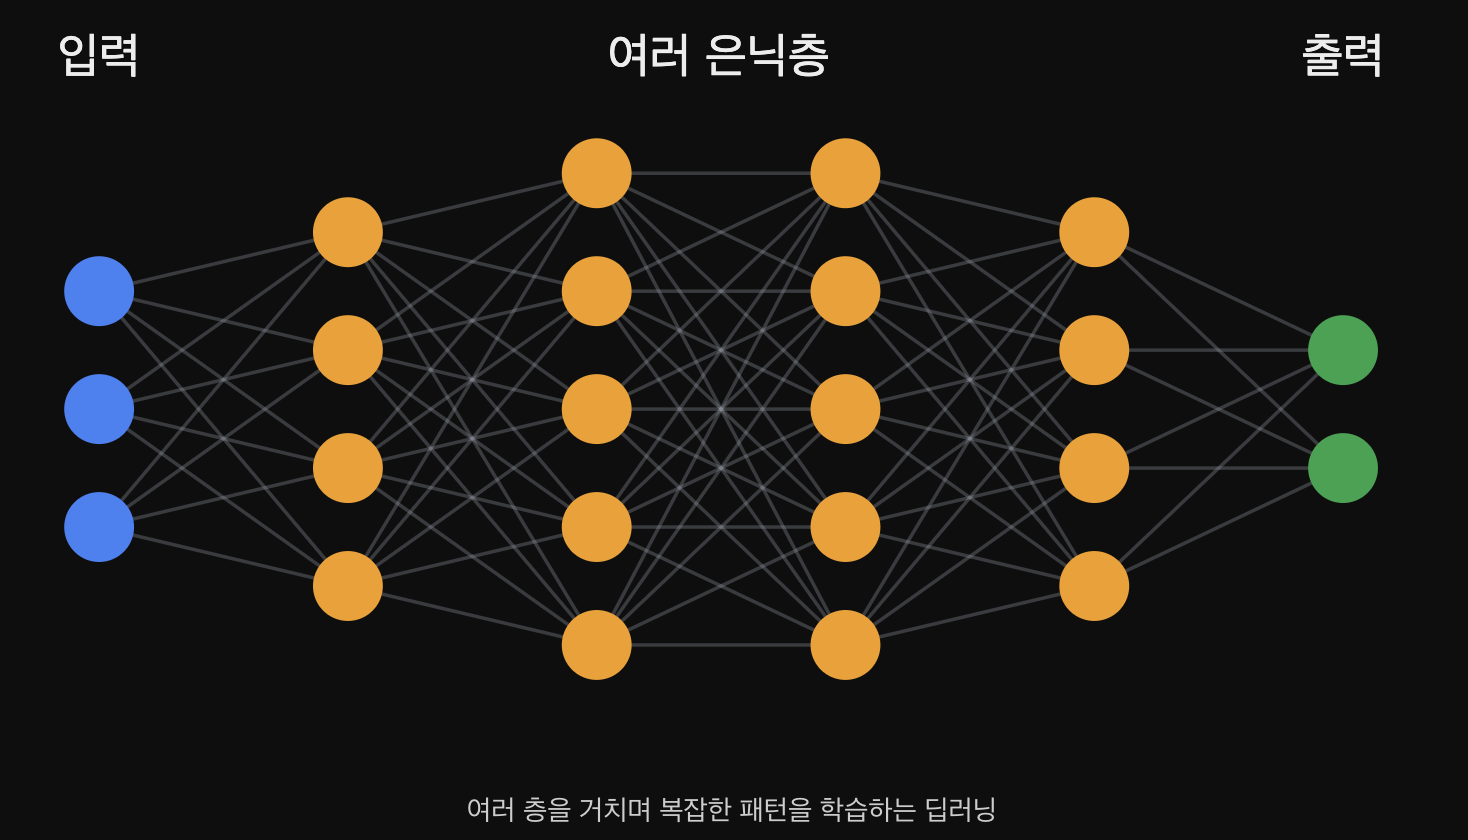

그림은 여러 은닉층을 가진 신경망의 연결 구조를 단순화한 예다. 파란 원은 입력값, 주황 원은 은닉 뉴런, 초록 원은 출력 뉴런을 나타낸다. 선은 계산값이 전달되는 연결이며 각 연결에는 가중치가 있다.
원의 개수는 구조를 설명하기 위한 예시이며, 실제 입력·출력의 크기와 뉴런 수는 데이터와 문제에 맞춰 정한다.

은닉층에서 계산한 값들을 중간 표현이라고 한다. 학습으로 가중치와 편향이 달라지면 중간 표현과 최종 예측도 달라진다.


### 활성화 함수

활성화 함수는 가중합과 편향으로 계산한 값을 변환한다. ReLU 같은 비선형 활성화 함수는 입력 구간에 따라 다르게 반응하도록 만들어, 신경망이 복잡한 관계를 표현할 수 있게 한다.

가중합과 편향만 계산하는 선형층을 두 번 연결하면 다음과 같이 하나의 계산으로 정리된다.

$$
h=2x+1, \qquad y=3h-2=3(2x+1)-2=6x+1
$$

$x$는 입력, $h$는 첫 번째 층의 결과, $y$는 최종 출력이다. 두 층을 거쳐도 가중치 6과 편향 1을 가진 하나의 선형층과 같으며, 입력과 출력의 관계는 직선이다.

ReLU는 다음과 같이 계산한다.

$$
\mathrm{ReLU}(z)=\max(0,z)
$$

음수 값은 0으로 만들고, 양수 값은 그대로 전달하므로 그래프가 0에서 꺾인다.
 여러 ReLU의 출력을 조합하면 구간마다 기울기가 다른 관계를 만들 수 있다.

\
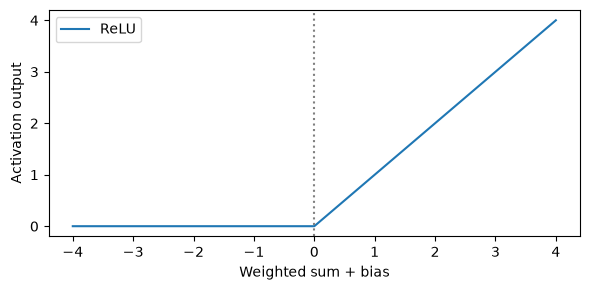


ReLU에 들어가는 값이 $x$, $x-2$, $x-4$인 뉴런 세 개를 생각해 보자. 편향에 따라 그래프가 꺾이는 위치가 각각 0, 2, 4가 된다.
세 뉴런의 출력에 가중치 1, -2, 1을 곱해 더하면 다음 함수를 얻는다.

$$
f(x)=\mathrm{ReLU}(x)-2\,\mathrm{ReLU}(x-2)+\mathrm{ReLU}(x-4)
$$

$f(x)$는 세 뉴런의 출력을 조합한 최종 결과다. 0~2에서는 증가하고, 2~4에서는 감소하며, 그 바깥에서는 0이 된다.
왼쪽 그래프는 각 뉴런의 출력, 오른쪽은 이를 조합한 결과다.

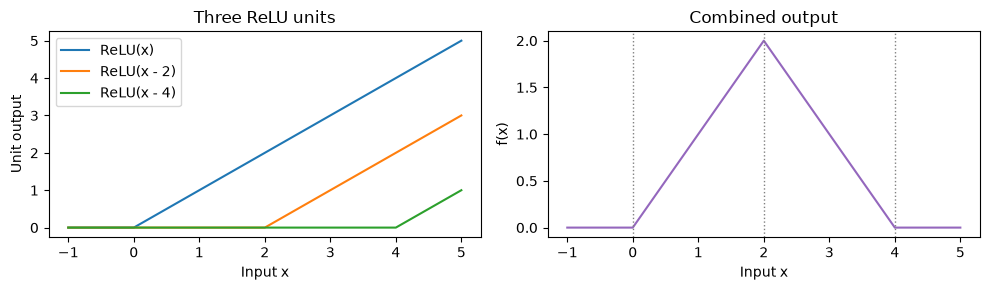


ReLU 하나는 두 구간에서 다르게 반응하고, 여러 ReLU의 출력을 조합하면 구간마다 기울기가 달라지는 관계를 만들 수 있다.
뉴런과 층을 늘려 이런 계산을 조합하면 곡선이나 복잡한 분류 경계를 근사할 수 있다. 학습은 데이터에 맞도록 가중치와 편향을 조정해 꺾이는 위치와 각 구간의 기울기를 바꾸는 과정이다.


### 손글씨 숫자 분류

손글씨 이미지의 픽셀 밝기를 입력으로 받아 0부터 9까지의 숫자를 구분하는 문제다.
같은 숫자도 획의 모양과 굵기가 다르다. MLP는 여러 픽셀을 조합해 은닉 값을 만들고, 이를 사용해 숫자별 점수를 계산한다.

### 손글씨 데이터 불러오기

`load_digits`는 scikit-learn에 포함된 손글씨 데이터를 불러온다. 총 1,797장의 이미지가 있으며, 각 이미지는 8행 8열의 흑백 픽셀로 이루어진다.
한 사례는 이미지 한 장이고, 정답은 이미지에 쓰인 숫자다.

| 항목 | 의미 |
| --- | --- |
| `images` | 이미지별 8×8 픽셀 배열 |
| `data` | 픽셀을 왼쪽 위부터 행 순서대로 펼친 64개 입력값 |
| `target` | 0부터 9까지의 정수 정답 |

픽셀 값은 0부터 16까지다. 값이 클수록 밝은 픽셀이다.


이미지: (1797, 8, 8) 입력: (1797, 64) 정답: (1797,)
픽셀 범위: 0.0 16.0


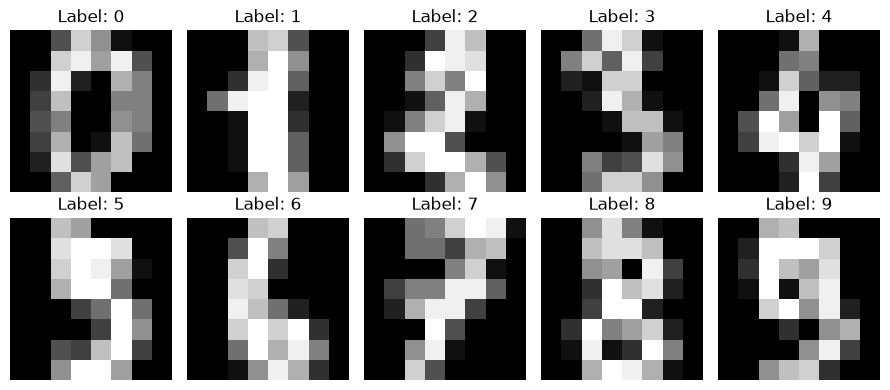

In [2]:
digits = load_digits()
X = digits.data  # NumPy 배열, (이미지 1797장, 픽셀 64개)
y = digits.target  # 정수 정답, (1797,)
print("이미지:", digits.images.shape, "입력:", X.shape, "정답:", y.shape)
print("픽셀 범위:", X.min(), X.max())

fig, axes = plt.subplots(2, 5, figsize=(9, 4))
for label, ax in enumerate(axes.flat):
    position = (y == label).nonzero()[0][0]  # 해당 숫자의 첫 이미지 위치
    ax.imshow(digits.images[position], cmap="gray", vmin=0, vmax=16)
    ax.set_title(f"Label: {label}")
    ax.axis("off")
plt.tight_layout()
plt.show()


### 신경망 입력으로 변환

텐서는 PyTorch에서 데이터를 담고 계산하는 데 사용하는 다차원 배열이다. NumPy 배열과 사용 방식이 비슷하며, GPU 연산과 학습에 필요한 자동 미분을 지원한다.

신경망에 넣기 전에 픽셀 값의 범위를 조정하는 전처리를 한다. 이 데이터의 픽셀 밝기는 0~16이므로, 16으로 나누어 0~1 범위로 맞춘다. 상대적인 밝기는 유지하면서 입력값의 크기를 줄여 안정적인 학습을 돕는다.


In [3]:
# tensor: 배열을 텐서로 변환한다. dtype=torch.float32: 32비트 실수로 저장한다.
inputs = torch.tensor(X / 16.0, dtype=torch.float32)  # (1797, 64)
print("신경망 입력 모양:", inputs.shape)
print("입력 범위:", inputs.min().item(), inputs.max().item())  # item(): 숫자 하나를 꺼낸다.


신경망 입력 모양: torch.Size([1797, 64])
입력 범위: 0.0 1.0


### 이미지와 펼친 입력 비교

이 실습의 모델은 표 데이터처럼 한 행에 담긴 특성값들을 받아 예측한다. 이미지 한 장으로 숫자 하나를 예측하므로, 한 이미지의 픽셀 64개를 한 행에 모아 입력한다.

이를 위해 8×8 이미지의 첫째 줄 8개, 둘째 줄 8개, …, 여덟째 줄 8개를 차례로 이어 붙인다. 그러면 이미지 한 장이 특성 64개를 가진 한 행이 된다. 이미지 3장을 입력하면 배열의 모양은 `(3, 64)`다.

그림은 이 변환을 보여 준다. 픽셀의 밝기는 그대로이며, 모든 이미지를 같은 순서로 펼치므로 같은 열은 항상 같은 픽셀 위치에 해당한다.


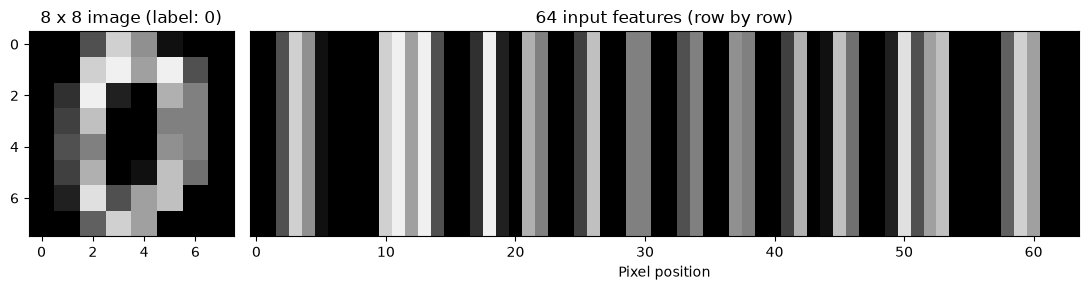

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3), gridspec_kw={"width_ratios": [1, 4]})
axes[0].imshow(digits.images[0] / 16.0, cmap="gray", vmin=0, vmax=1)
axes[0].set_title(f"8 x 8 image (label: {y[0]})")
# numpy(): CPU 텐서를 NumPy 배열로 변환한다. reshape(1, 64): 한 줄로 표시한다.
axes[1].imshow(inputs[0].numpy().reshape(1, 64), cmap="gray", vmin=0, vmax=1, aspect="auto")
axes[1].set_title("64 input features (row by row)")
axes[1].set_xlabel("Pixel position")
axes[1].set_yticks([])
plt.tight_layout()
plt.show()


## 다층 퍼셉트론으로 예측하기

퍼셉트론은 간단한 형태의 인공 뉴런 모델이다. 여러 입력에 가중치를 곱해 더하고 편향을 더한 뒤, 기준값에 따라 0 또는 1을 출력해 두 클래스를 구분한다.

다층 퍼셉트론(MLP)은 퍼셉트론의 계산 방식을 확장해 여러 뉴런을 층으로 묶어 연결한 신경망이다. 완전연결층의 각 뉴런은 앞 층의 모든 값을 입력으로 사용하며, 은닉층에서는 ReLU 같은 비선형 활성화 함수를 적용해 복잡한 관계를 학습한다.

손글씨 숫자 분류에서는 픽셀 64개를 은닉 값 32개로 바꾸고, 이를 조합해 숫자 0~9의 점수 10개를 출력한다.

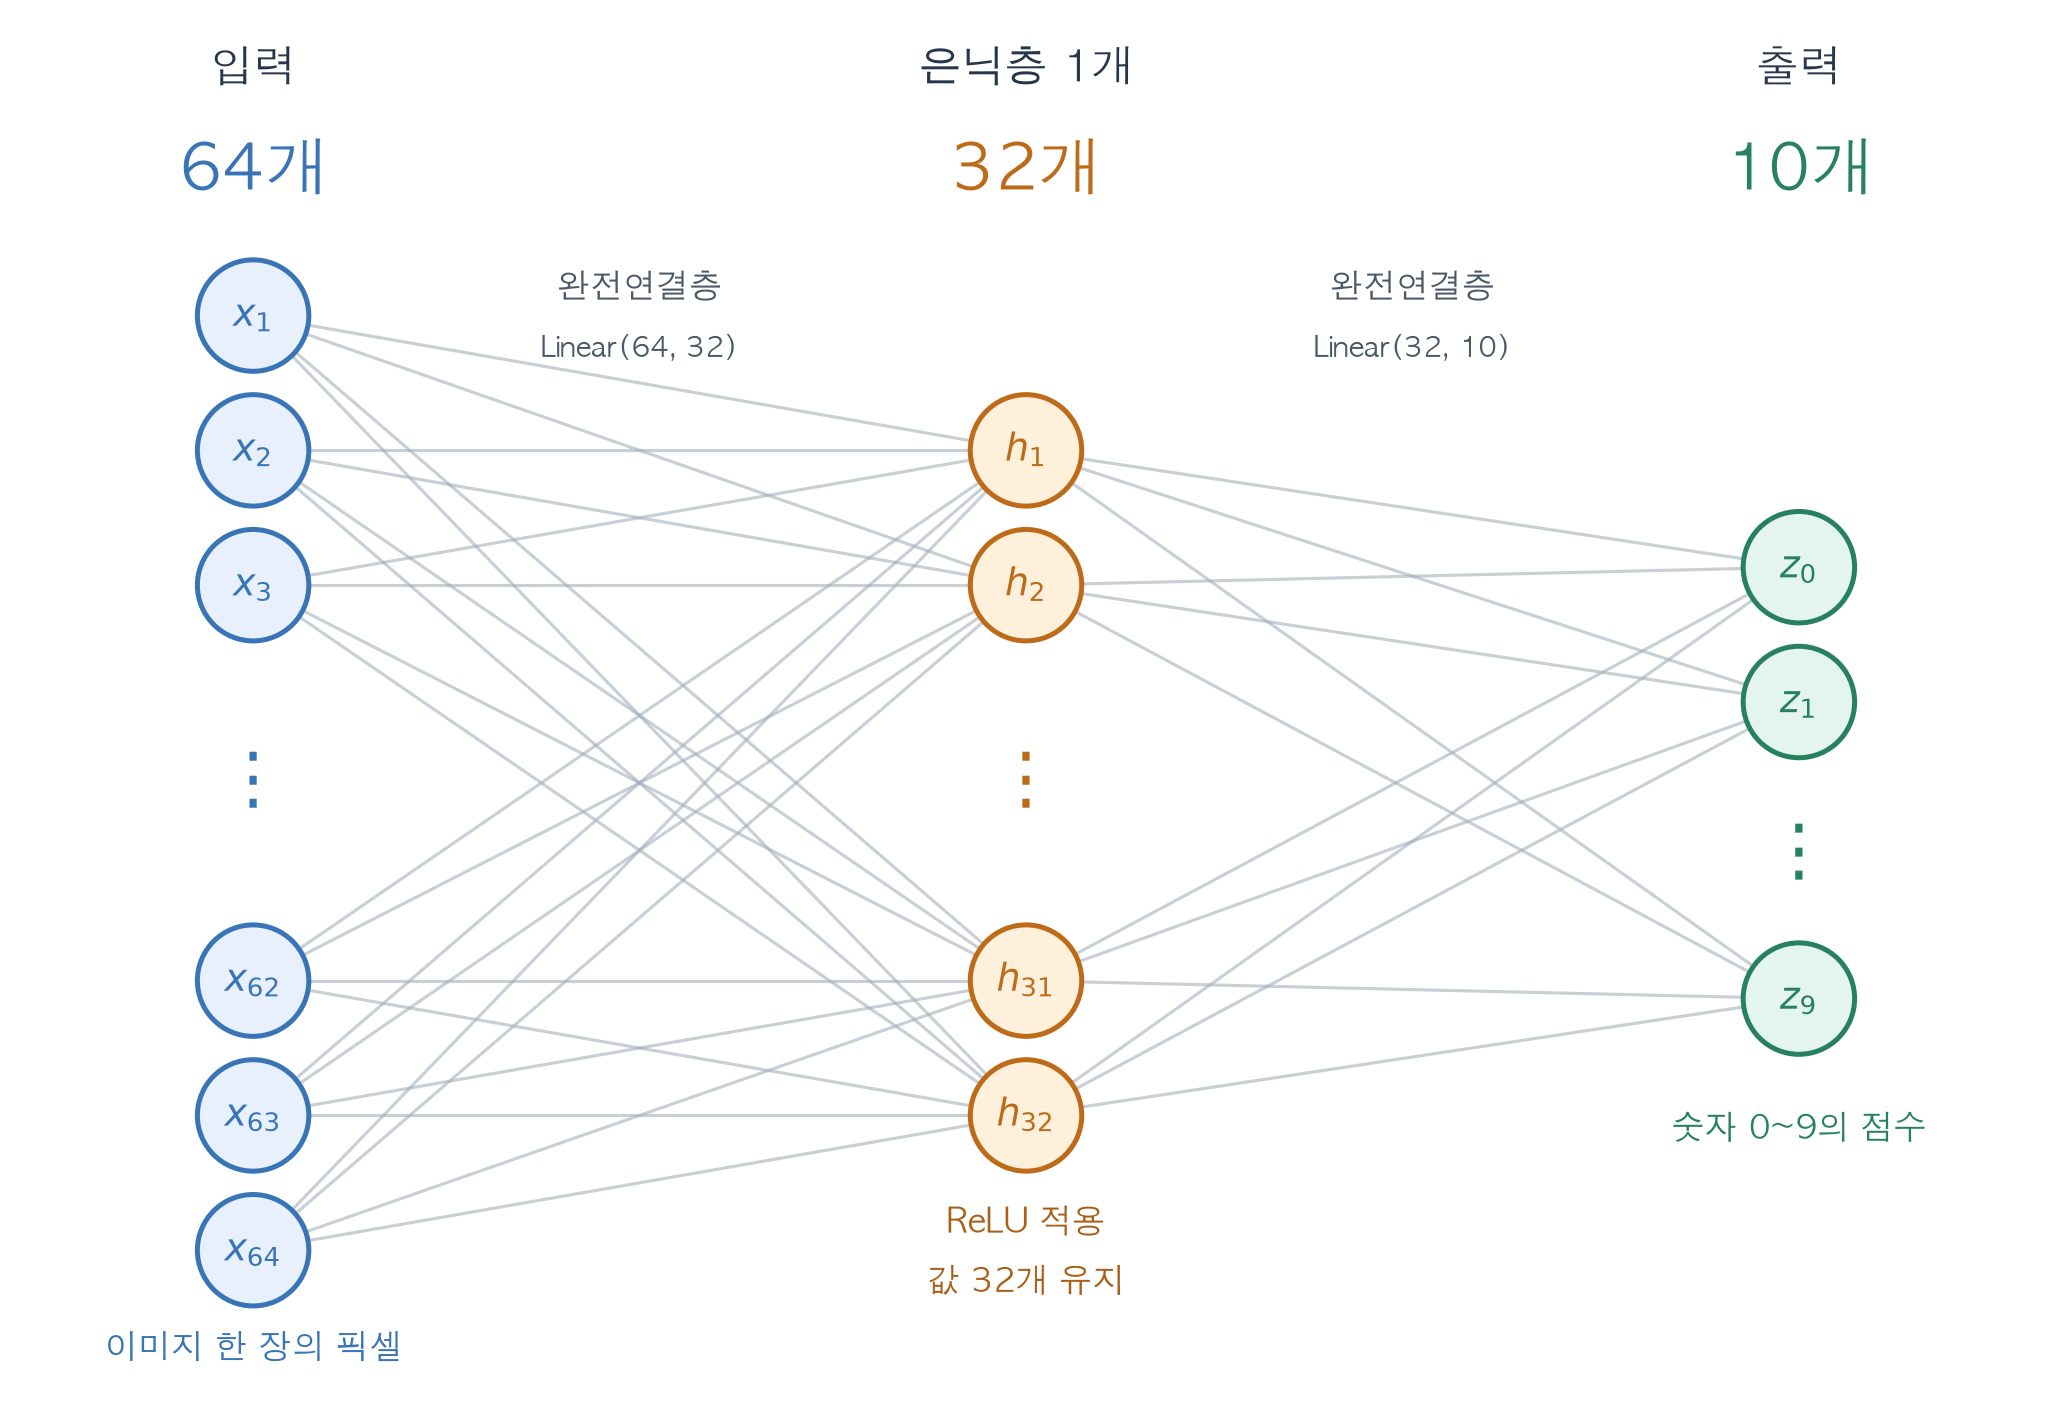

은닉층의 뉴런 32개는 각각 입력 픽셀 64개를 모두 받아 계산한다. ReLU는 계산한 값들을 변환하며 개수는 32개로 유지한다. 출력층은 이 값 32개를 받아 숫자별 점수 10개를 만든다.

입력부터 출력을 차례로 계산하는 과정을 순전파라고 한다. `nn.Linear`는 가중합과 편향을 계산하고, `nn.ReLU`는 활성화를 적용한다. `nn.Sequential`은 층을 적은 순서대로 연결한다.
이 작은 MLP는 은닉층을 하나 사용한다. 입력 크기는 픽셀 수, 출력 크기는 분류할 숫자의 종류에 맞춰 정한다.


In [7]:
def make_model(hidden_size=32):
    return nn.Sequential(
        nn.Linear(64, hidden_size),  # 입력 픽셀 수 → 은닉 값 수
        nn.ReLU(),
        nn.Linear(hidden_size, 10),  # 은닉 값 수 → 클래스 수
    )

model = make_model()
print(model)


Sequential(
  (0): Linear(in_features=64, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=10, bias=True)
)


### 점수에서 예측으로

이미지 한 장을 넣으면 모델은 숫자 0부터 9까지 각각에 점수를 매긴다. 이렇게 나온 점수를 로짓이라고 한다.

이 점수에 Softmax를 적용하면 숫자별 예측 확률을 얻는다. 점수가 높은 숫자일수록 확률도 높고, 열 개의 확률을 모두 더하면 1이 된다. 그중 확률이 가장 높은 숫자가 모델의 예측이다.

이 예제는 이미지 입력에서 점수·확률을 거쳐 예측 숫자를 얻는 하나의 흐름을 보여 준다. 모델은 아직 학습 전이며, 현재 결과는 초기 가중치와 편향으로 계산한 예측이다.


,actual,predicted
0,0,6
1,1,6
2,2,6


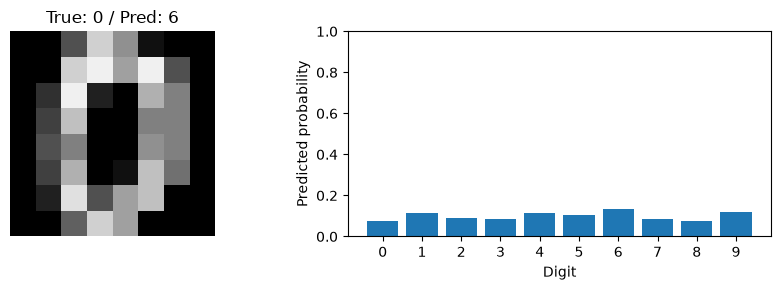

In [ ]:
with torch.no_grad():  # 학습 없이 예측만 계산한다.
    logits = model(inputs)  # 전체 이미지 1797장 → (1797, 10)
    probabilities = torch.softmax(logits, dim=1)  # dim=1: 클래스 축
predictions = probabilities.argmax(dim=1)  # 이미지별 최대 확률의 클래스 위치, (1797,)
prediction_results = pd.DataFrame({"actual": y, "predicted": predictions.numpy()})
display(prediction_results.head(3))  # 결과 표는 처음 3개만 표시한다.

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].imshow(digits.iy655y5t45e4dfhtshtsththrsthtㅁㄴㅇㅁㄴㅇㅁㄴㅇmages[0], cmap="gray", vmin=0, vmax=16)
axes[0].set_title(f"True: {y[0]} / Pred: {predictions[0].item()}")
axes[0].axis("off")
axes[1].bar(range(10), probabilities[0].numpy())
axes[1].set(xticks=range(10), xlabel="Digit", ylabel="Predicted probability", ylim=(0, 1))
plt.tight_layout()
plt.show()
